# Limpieza y análisis de ventas — Almacén Online Ejemplo (2025)

**Objetivo:** transformar una exportación de ventas desordenada en un dataset confiable y responder preguntas de negocio:

1. ¿Cómo evolucionaron las ventas a lo largo del año?
2. ¿Qué provincias, categorías y productos generan más ingresos?
3. ¿Qué medios de pago usan los clientes y cuánto gastan por pedido?

> **Nota:** los datos son **simulados** (empresa ficticia), generados con `src/generar_datos.py` para reproducir los problemas típicos de un archivo real: duplicados, fechas en varios formatos, montos con formato argentino, nombres inconsistentes, faltantes y errores de carga.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

# Estilo de gráficos: paleta sobria y consistente
AZUL, NARANJA, VERDE_AGUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXTO, TEXTO_2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRILLA, "axes.labelcolor": TEXTO_2, "axes.titlecolor": TEXTO,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRILLA, "grid.linewidth": 0.8, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "font.size": 10, "axes.axisbelow": True,
})

def formato_ar(x, decimales=0):
    # Número en formato argentino: 1.234.567,89
    return f"{x:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def millones(x, _):
    return f"$ {formato_ar(x / 1e6, 1)} M"

## 1. Carga e inspección inicial

In [2]:
crudo = pd.read_csv("../data/raw/ventas_crudas.csv", dtype=str)
print(f"Filas: {formato_ar(len(crudo))} | Columnas: {crudo.shape[1]}")
crudo.head(8)

Filas: 5.120 | Columnas: 10

,id_pedido,fecha,cliente_id,provincia,categoria,producto,cantidad,precio_unitario,total,medio_pago
0,P10530,2025-05-10,C1094,CORDOBA,Almacén,Yerba 1kg,1,4799.04,"$ 4.799,04",Transferencia
1,P11729,06/08/2025,C0426,CABA,Almacen,Café molido 500g,2,9168.35,"$ 18.336,70",Tarjeta de débito
2,P11010,2025-01-27,C0279,Bs As,limpieza,Jabón polvo 3kg,4,10147.04,"$ 40.588,17",Tarjeta de débito
3,P11149,2025-03-10,C0668,Bs. As.,BEBIDAS,Cerveza lata x6,1,7371.86,"$ 7.371,86",Transferencia
4,P11383,03/06/2025,C0278,Entre Ríos,Perfumeria,Desodorante,6,3549.5,"$ 21.297,00",Tarjeta de débito
5,P14102,2025-06-26,C1397,SANTA FE,bebidas,Vino Malbec 750ml,2,NaN,14355.31,Tarjeta de crédito
6,P14857,20-09-2025,C1030,BUENOS AIRES,Perfumería,Shampoo 400ml,1,5485.89,5485.89,Transferencia
7,P14915,06/08/2025,C0846,buenos aires,Bebidas,Agua 2L,2,1407.82,2815.64,Mercado Pago


In [3]:
resumen = pd.DataFrame({
    "faltantes": crudo.isna().sum(),
    "% faltantes": (crudo.isna().mean() * 100).round(1),
    "valores únicos": crudo.nunique(),
})
print("Filas duplicadas exactas:", crudo.duplicated().sum())
resumen

Filas duplicadas exactas: 120

,faltantes,% faltantes,valores únicos
id_pedido,0,0.0,5000
fecha,0,0.0,1195
cliente_id,102,2.0,1351
provincia,153,3.0,25
categoria,0,0.0,10
producto,0,0.0,30
cantidad,0,0.0,8
precio_unitario,103,2.0,4883
total,0,0.0,4993
medio_pago,204,4.0,5


In [4]:
# Problemas visibles a simple vista
print("Provincias tal como vienen:\n", sorted(crudo["provincia"].dropna().unique()), "\n")
print("Categorías tal como vienen:\n", sorted(crudo["categoria"].dropna().unique()), "\n")
print("Ejemplos de fechas:", crudo["fecha"].sample(6, random_state=1).tolist())
print("Ejemplos de totales:", crudo["total"].sample(6, random_state=3).tolist())

Provincias tal como vienen:
 ['BUENOS AIRES', 'Bs As', 'Bs. As.', 'Buenos Aires', 'C.A.B.A.', 'CABA', 'CORDOBA', 'Capital Federal', 'Ciudad de Buenos Aires', 'Cordoba', 'Córdoba', 'Entre Rios', 'Entre Ríos', 'Mendoza', 'Neuquen', 'Neuquén', 'SANTA FE', 'Salta', 'Santa Fe', 'Santa fe', 'Tucuman', 'Tucumán', 'buenos aires', 'córdoba ', 'mendoza'] 

Categorías tal como vienen:
 ['ALMACEN', 'Almacen', 'Almacén', 'BEBIDAS', 'Bebidas', 'Limpieza', 'Perfumeria', 'Perfumería', 'bebidas', 'limpieza'] 

Ejemplos de fechas: ['2025-08-02', '24/08/2025', '28/08/2025', '20/08/25', '2025-09-03', '21/02/2025']
Ejemplos de totales: ['16761.97', '$ 48.384,87', '$ 9.632,26', '$ 20.390,38', '6673.60', '$ 7.413,68']

**Diagnóstico:**
- Hay pedidos duplicados (la misma exportación se cargó dos veces).
- La misma provincia aparece escrita de varias formas (`Bs As`, `BUENOS AIRES`, `Capital Federal`, `CABA`…).
- Las fechas vienen en 4 formatos distintos.
- La columna `total` mezcla números con texto en formato argentino (`$ 1.234,50`).
- Hay faltantes en provincia, medio de pago, cliente y precio, y espacios de más en los productos.

## 2. Limpieza

La lógica de limpieza vive en **`src/limpiar_datos.py`**, un script reutilizable que también se puede correr desde la terminal con cualquier exportación nueva:

```bash
python src/limpiar_datos.py data/raw/ventas_crudas.csv data/processed/ventas_limpias.csv
```

Acá se importa y se muestra qué hace cada paso. Así el notebook queda para explicar y analizar, y el script, para trabajar en producción.

| Paso | Qué resuelve |
|---|---|
| Eliminar duplicados | Pedidos exportados dos veces |
| Unificar nombres | `Bs As`, `BUENOS AIRES` → `Buenos Aires` |
| Convertir tipos | 4 formatos de fecha y montos `$ 1.234,50` |
| Excluir cantidades ≤ 0 | Errores de carga que no se pueden corregir con seguridad |
| Completar precios | Precio faltante = total / cantidad |
| Corregir totales | Totales que no coinciden con precio × cantidad (ej. un total que perdió la coma decimal) |
| Marcar faltantes | Provincia o medio de pago vacíos → `Sin dato`, sin inventar valores |

In [5]:
import sys

sys.path.insert(0, "../src")
from limpiar_datos import limpiar_ventas, parsear_fecha, parsear_monto

# Las funciones de conversión con ejemplos reales del archivo
for t in ["$ 18.336,70", "14355.31", "$ 4.799,04"]:
    print(f"{t!r:>15} -> {formato_ar(parsear_monto(t), 2)}")
for f in ["2025-08-02", "24/08/2025", "20-09-2025", "20/08/25"]:
    print(f"{f!r:>15} -> {parsear_fecha(f).date()}")

  '$ 18.336,70' -> 18.336,70
     '14355.31' -> 14.355,31
   '$ 4.799,04' -> 4.799,04
   '2025-08-02' -> 2025-08-02
   '24/08/2025' -> 2025-08-24
   '20-09-2025' -> 2025-09-20
     '20/08/25' -> 2025-08-20

In [6]:
df, log = limpiar_ventas(crudo)
print(f"{formato_ar(len(crudo))} filas crudas -> {formato_ar(len(df))} pedidos limpios")
log

5.120 filas crudas -> 4.975 pedidos limpios

,paso,filas_antes,filas_despues,detalle
0,Eliminar duplicados exactos,5120,5000,120 filas repetidas
1,Unificar nombres,5000,5000,provincias y categorías unificadas
2,Convertir fechas y montos,5000,5000,"4 formatos de fecha y montos '$ 1.234,50' convertidos"
3,Excluir cantidades <= 0,5000,4975,25 pedidos con error de carga
4,Completar precio unitario,4975,4975,99 precios calculados como total/cantidad
5,Corregir totales inconsistentes,4975,4975,8 totales recalculados (diferencia de $ 4.150.116)
6,Marcar provincia faltante,4975,4975,150 valores como 'Sin dato'
7,Marcar medio_pago faltante,4975,4975,198 valores como 'Sin dato'
8,Cliente faltante,4975,4975,100 pedidos sin cliente (se mantienen)


In [7]:
# Los 8 totales corregidos: perdieron la coma decimal ("5042,21" quedó como 504221)
esperado = pd.to_numeric(crudo["precio_unitario"], errors="coerce") * pd.to_numeric(crudo["cantidad"], errors="coerce")
total_crudo = crudo["total"].map(parsear_monto)
cant = pd.to_numeric(crudo["cantidad"], errors="coerce")
errores = crudo[((total_crudo / esperado - 1).abs() > 0.01) & (cant > 0)].drop_duplicates()
print(f"{len(errores)} pedidos con total inflado")
errores[["id_pedido", "producto", "cantidad", "precio_unitario", "total"]].head()

8 pedidos con total inflado

,id_pedido,producto,cantidad,precio_unitario,total
640,P10533,Gaseosa 2.25L,2,3332.96,666591
2282,P12267,Yerba 1kg,1,5042.21,504221
2471,P14347,Shampoo 400ml,2,5018.2,1003639
2474,P11326,Agua 2L,4,1277.95,511182
2969,P14907,Pasta dental,1,2315.39,231539


In [8]:
df.to_csv("../data/processed/ventas_limpias.csv", index=False, date_format="%Y-%m-%d")

# Columnas auxiliares para el análisis
df["mes"] = df["fecha"].dt.to_period("M")
df["dia_semana"] = df["fecha"].dt.dayofweek
df.head()

,id_pedido,fecha,cliente_id,provincia,categoria,producto,cantidad,precio_unitario,total,medio_pago,mes,dia_semana
0,P10078,2025-01-01,C0041,Buenos Aires,Limpieza,Detergente 750ml,1,2101.72,2101.72,Transferencia,2025-01,2
1,P10364,2025-01-01,C1095,Buenos Aires,Perfumería,Pasta dental,3,2087.51,6262.54,Tarjeta de crédito,2025-01,2
2,P10480,2025-01-01,C0556,Córdoba,Almacén,Yerba 1kg,3,4313.30,12939.89,Mercado Pago,2025-01,2
3,P10645,2025-01-01,C0347,Buenos Aires,Almacén,Yerba 1kg,3,4133.52,12400.55,Tarjeta de crédito,2025-01,2
4,P11024,2025-01-01,C0085,CABA,Almacén,Arroz 1kg,1,1758.85,1758.85,Mercado Pago,2025-01,2


## 3. Análisis

In [9]:
total_ventas = df["total"].sum()
kpis = pd.Series({
    "Facturación total": f"$ {total_ventas:,.0f}".replace(",", "."),
    "Pedidos": f"{len(df):,}".replace(",", "."),
    "Unidades vendidas": f"{df['cantidad'].sum():,}".replace(",", "."),
    "Ticket promedio": f"$ {df['total'].mean():,.0f}".replace(",", "."),
    "Clientes distintos": f"{df['cliente_id'].nunique():,}".replace(",", "."),
})
kpis.to_frame("2025")

,2025
Facturación total,$ 58.430.607
Pedidos,4.975
Unidades vendidas,12.560
Ticket promedio,$ 11.745
Clientes distintos,1.351


### 3.1 Evolución mensual

La facturación en pesos sube en parte por la **inflación** (los precios aumentan mes a mes). Por eso se muestran por separado la facturación y las **unidades vendidas**, que reflejan el volumen real.

Facturación dic vs ene: +103%
Unidades en diciembre vs promedio ene-nov: +48%

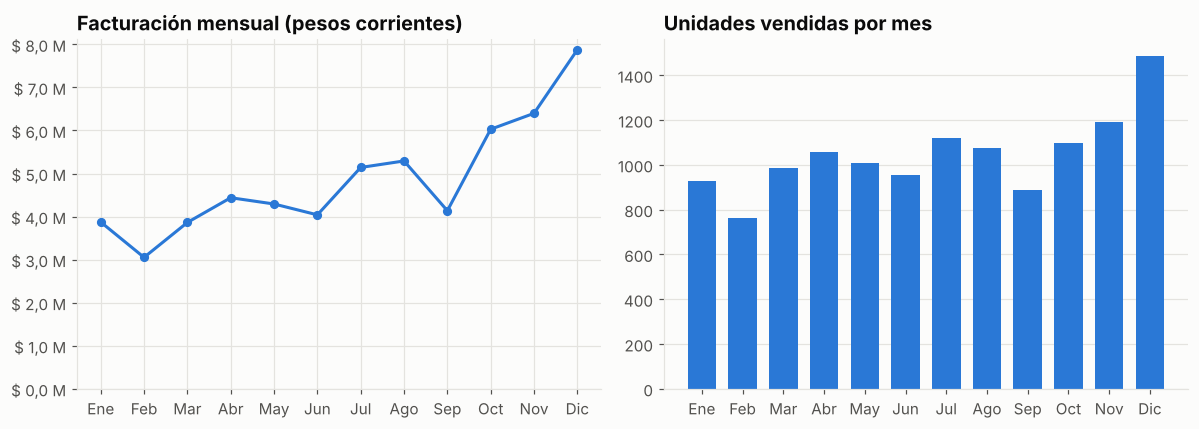

In [10]:
mensual = df.groupby("mes").agg(facturacion=("total", "sum"), unidades=("cantidad", "sum"),
                                 pedidos=("id_pedido", "count"))
mensual.index = mensual.index.to_timestamp()
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
etiquetas = [MESES[m - 1] for m in mensual.index.month]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(etiquetas, mensual["facturacion"], color=AZUL, linewidth=2, marker="o", markersize=5)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(millones))
axes[0].set_title("Facturación mensual (pesos corrientes)")
axes[0].set_ylim(0)

axes[1].bar(etiquetas, mensual["unidades"], color=AZUL, width=0.7)
axes[1].set_title("Unidades vendidas por mes")
axes[1].grid(axis="x", visible=False)
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../figures/01_evolucion_mensual.png", dpi=150, bbox_inches="tight")

crec = mensual["facturacion"].iloc[-1] / mensual["facturacion"].iloc[0] - 1
dic_vs_prom = mensual["unidades"].iloc[-1] / mensual["unidades"].iloc[:-1].mean() - 1
print(f"Facturación dic vs ene: {crec:+.0%}")
print(f"Unidades en diciembre vs promedio ene-nov: {dic_vs_prom:+.0%}")

### 3.2 Ventas por provincia

Top 3 provincias: Buenos Aires 38%, CABA 19%, Córdoba 11% | juntas: 68%

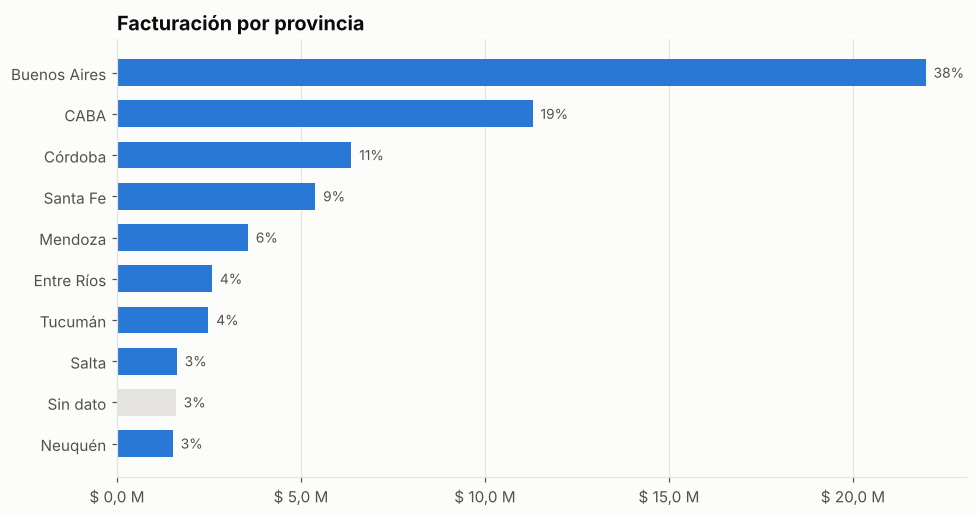

In [11]:
prov = df.groupby("provincia")["total"].sum().sort_values()
participacion = prov / prov.sum()

fig, ax = plt.subplots(figsize=(9, 4.8))
colores = [GRILLA if p == "Sin dato" else AZUL for p in prov.index]
ax.barh(prov.index, prov.values, color=colores, height=0.65)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(millones))
ax.grid(axis="y", visible=False)
for y, (v, p) in enumerate(zip(prov.values, participacion.values)):
    ax.text(v, y, f"  {p:.0%}", va="center", color=TEXTO_2, fontsize=9)
ax.set_title("Facturación por provincia")
plt.tight_layout()
plt.savefig("../figures/02_provincias.png", dpi=150, bbox_inches="tight")

top3 = participacion.drop("Sin dato", errors="ignore").sort_values(ascending=False).head(3)
print("Top 3 provincias:", ", ".join(f"{k} {v:.0%}" for k, v in top3.items()), f"| juntas: {top3.sum():.0%}")

### 3.3 Categorías y productos

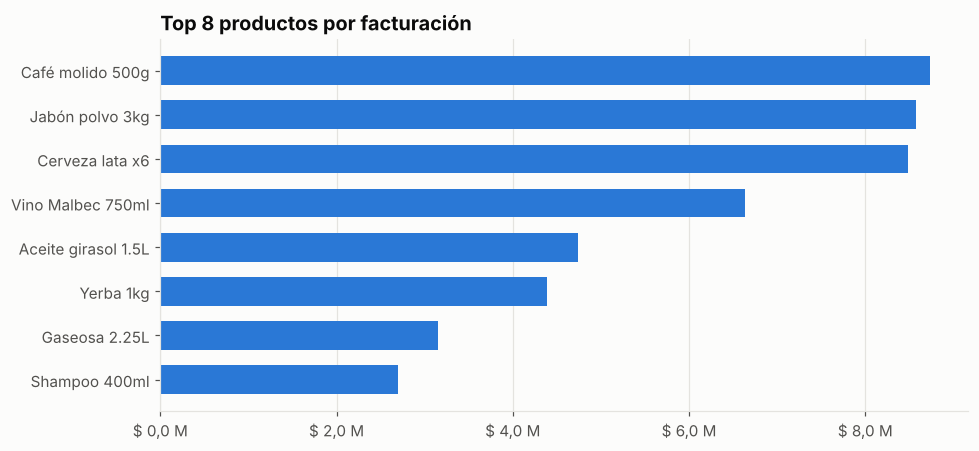

,facturacion,unidades,% facturación
categoria,,,
Almacén,$ 21.323.352,4911,36.5
Bebidas,$ 19.619.082,3802,33.6
Limpieza,$ 11.814.645,2306,20.2
Perfumería,$ 5.673.528,1541,9.7


In [12]:
cat = df.groupby("categoria").agg(facturacion=("total", "sum"), unidades=("cantidad", "sum"))
cat["% facturación"] = (cat["facturacion"] / cat["facturacion"].sum() * 100).round(1)
cat = cat.sort_values("facturacion", ascending=False)

productos = (df.groupby(["producto", "categoria"])["total"].sum()
               .sort_values(ascending=False).head(8).reset_index())

fig, ax = plt.subplots(figsize=(9, 4.2))
orden = productos.iloc[::-1]
ax.barh(orden["producto"], orden["total"], color=AZUL, height=0.65)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(millones))
ax.grid(axis="y", visible=False)
ax.set_title("Top 8 productos por facturación")
plt.tight_layout()
plt.savefig("../figures/03_top_productos.png", dpi=150, bbox_inches="tight")

cat.assign(facturacion=cat["facturacion"].map(lambda x: f"$ {x:,.0f}".replace(",", ".")))

### 3.4 Medios de pago y ticket promedio

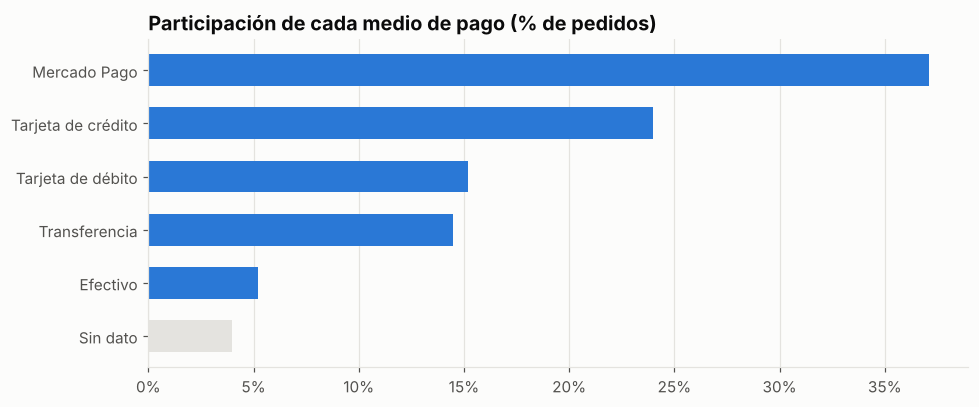

,pedidos,ticket_promedio,% pedidos
medio_pago,,,
Mercado Pago,1847,$ 11.737,37.1
Tarjeta de crédito,1196,$ 12.027,24.0
Tarjeta de débito,758,$ 11.776,15.2
Transferencia,719,$ 11.942,14.5
Efectivo,257,$ 11.141,5.2
Sin dato,198,$ 10.064,4.0


In [13]:
pago = df.groupby("medio_pago").agg(pedidos=("id_pedido", "count"), ticket_promedio=("total", "mean"))
pago["% pedidos"] = (pago["pedidos"] / pago["pedidos"].sum() * 100).round(1)
pago = pago.sort_values("pedidos", ascending=False)

fig, ax = plt.subplots(figsize=(9, 3.8))
orden = pago.iloc[::-1]
colores = [GRILLA if m == "Sin dato" else AZUL for m in orden.index]
ax.barh(orden.index, orden["% pedidos"], color=colores, height=0.6)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.set_title("Participación de cada medio de pago (% de pedidos)")
plt.tight_layout()
plt.savefig("../figures/04_medios_pago.png", dpi=150, bbox_inches="tight")

pago.assign(ticket_promedio=pago["ticket_promedio"].map(lambda x: f"$ {x:,.0f}".replace(",", ".")))

### 3.5 Día de la semana

Viernes a domingo vs lunes a jueves: +24% pedidos por día

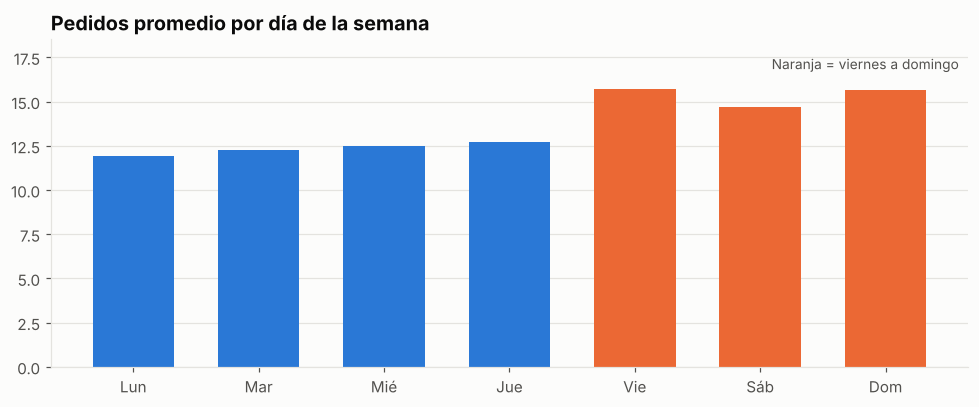

In [14]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
# Promedio de pedidos por día (no total), para no sesgar por cantidad de lunes/martes en el año
por_dia = df.groupby([df["fecha"].dt.date, "dia_semana"]).size().reset_index(name="pedidos")
prom_dia = por_dia.groupby("dia_semana")["pedidos"].mean().reindex(range(7))

fig, ax = plt.subplots(figsize=(9, 3.8))
colores = [NARANJA if d >= 4 else AZUL for d in range(7)]
ax.bar(dias, prom_dia.values, color=colores, width=0.65)
ax.grid(axis="x", visible=False)
ax.set_title("Pedidos promedio por día de la semana")
ax.set_ylim(0, prom_dia.max() * 1.18)
ax.text(0.99, 0.95, "Naranja = viernes a domingo", transform=ax.transAxes, ha="right", va="top", color=TEXTO_2, fontsize=9)
plt.tight_layout()
plt.savefig("../figures/05_dia_semana.png", dpi=150, bbox_inches="tight")

finde = prom_dia.loc[4:6].mean() / prom_dia.loc[0:3].mean() - 1
print(f"Viernes a domingo vs lunes a jueves: {finde:+.0%} pedidos por día")

## 4. Conclusiones

**Sobre la calidad de los datos**
- El archivo original tenía 5.120 filas; después de la limpieza quedan **4.975 pedidos válidos**. Se eliminaron 120 duplicados y 25 pedidos con cantidades imposibles, y se corrigieron 8 totales que habían perdido la coma decimal al importarse (por ejemplo, un pedido de yerba de $ 5.042,21 figuraba como $ 504.221).
- Si no se corregían esos 8 errores, la facturación del año quedaba inflada en unos $ 4,2 millones (un 7% más): un error chico en cantidad de filas puede distorsionar mucho los totales.
- **Recomendación:** validar en el sistema de carga que la cantidad sea mayor a 0 y que el total coincida con precio × cantidad, y usar listas desplegables para provincia y categoría.

**Sobre el negocio**
1. **Diciembre es el mes clave:** se vendieron un 48% más de unidades que el promedio del resto del año. Conviene reforzar stock y logística desde noviembre, que también viene en alza.
2. **La facturación se duplicó de enero a diciembre, pero no todo es crecimiento real:** gran parte se explica por los aumentos de precios. Para medir el crecimiento real, mirar unidades vendidas o ajustar por inflación.
3. **Alta concentración geográfica:** Buenos Aires, CABA y Córdoba suman el 68% de la facturación. Hay margen para crecer en el interior (Mendoza, Tucumán, Salta, Neuquén).
4. **Almacén y Bebidas generan el 70% de los ingresos.** Café, jabón en polvo y cerveza son los productos que más facturan.
5. **Mercado Pago domina los pagos (37% de los pedidos)** y el ticket promedio es similar en todos los medios, así que no hace falta ofrecer descuentos para mover a los clientes de un medio a otro.
6. **De viernes a domingo hay un 24% más de pedidos por día** que de lunes a jueves: es el mejor momento para lanzar promociones.